In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.preprocessing import StandardScaler
import numpy as np


In [12]:
train_df = pd.read_csv("../data/processed/train.csv")

In [13]:
train_df.head()

,item_id,waist,size,quality,cup size,hips,bra size,category,bust,height,user_name,length,fit,user_id,shoe size,shoe width,review_summary,review_text,fit_label
0,124024,NaN,9,5.0,c,42.0,38.0,new,38.0,5ft 2in,Colleen,slightly short,fit,629330,7.0,average,NaN,NaN,1
1,200824,NaN,1,4.0,a,35.0,32.0,dresses,NaN,5ft,Christine,slightly long,large,790006,5.0,average,Great versatile dress,Great versatile dress,2
2,477210,NaN,8,4.0,d,34.0,34.0,tops,NaN,5ft 5in,jdierk,just right,fit,521918,NaN,NaN,very flattering. medium,very flattering. medium is a perfect fit. fab...,1
3,654585,NaN,20,4.0,b,47.0,38.0,bottoms,NaN,5ft 1in,gonzalezb1459,slightly long,large,700500,NaN,NaN,very wrinkly material. be,very wrinkly material. because of the pockets ...,2
4,715662,NaN,8,4.0,c,35.0,36.0,bottoms,NaN,5ft 11in,Nicole,just right,small,905961,NaN,NaN,These just didn't look ri,These just didn't look right on me. I think th...,0


In [14]:
print(train_df['fit'].value_counts(normalize=True).round(4))

fit
fit      0.6856
large    0.1577
small    0.1567
Name: proportion, dtype: float64


In [15]:
missing_pct = (train_df.isna().mean()* 100).sort_values(ascending=False)
print(missing_pct.round(2))

waist             96.53
bust              85.63
shoe width        77.55
shoe size         66.34
hips              32.12
review_text        8.15
review_summary     8.15
cup size           7.50
bra size           7.21
height             1.32
quality            0.08
length             0.04
item_id            0.00
size               0.00
category           0.00
user_name          0.00
fit                0.00
user_id            0.00
fit_label          0.00
dtype: float64


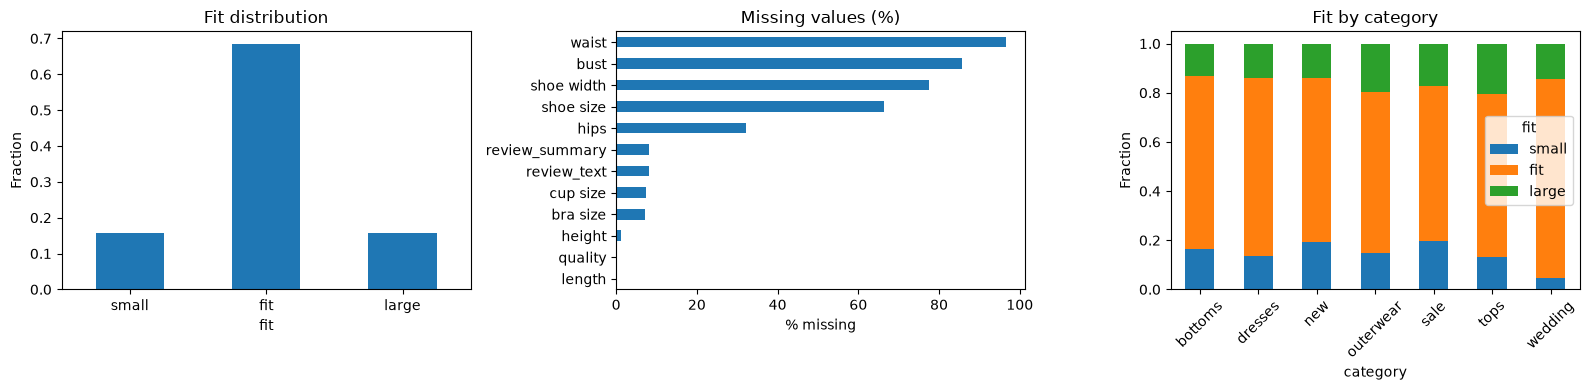

In [29]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# class balance
fit_counts = train_df["fit"].value_counts(normalize=True)[["small", "fit", "large"]]
fit_counts.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Fit distribution")
axes[0].set_ylabel("Fraction")

# missingness
missing = train_df.isna().mean() * 100
missing = missing[missing > 0].sort_values()
missing.plot(kind="barh", ax=axes[1])
axes[1].set_title("Missing values (%)")
axes[1].set_xlabel("% missing")

# fit by category
ct = pd.crosstab(train_df["category"], train_df["fit"], normalize="index")[["small", "fit", "large"]]
ct.plot(kind="bar", stacked=True, ax=axes[2], rot=45)
axes[2].set_title("Fit by category")
axes[2].set_ylabel("Fraction")

plt.tight_layout()
plt.show()

In [16]:
user_counts = train_df["user_id"].value_counts()
item_counts = train_df["item_id"].value_counts()
print(f"\nUnique users: {len(user_counts)} | One-time users: {(user_counts == 1).sum()} ({(user_counts == 1).mean():.1%})")
print(f"Unique items: {len(item_counts)} | One-time items: {(item_counts == 1).sum()} ({(item_counts == 1).mean():.1%})")


Unique users: 41155 | One-time users: 28642 (69.6%)
Unique items: 1295 | One-time items: 334 (25.8%)


In [17]:
keep_cols = ["size", "category", "height", "hips", "bra size", "cup size"]

for col in keep_cols:
    print(f"\n--- {col} (dtype: {train_df[col].dtype}) ---")
    print("Unique count:", train_df[col].nunique())
    print("Top 10 values:")
    print(train_df[col].value_counts(dropna=False).head(10))

print("\n--- Fit Proportion by Category ---")
cat_fit = pd.crosstab(train_df["category"], train_df["fit"], normalize="index")
print(cat_fit.round(3))


--- size (dtype: int64) ---
Unique count: 29
Top 10 values:
size
8     14369
12    13853
4     11079
20     5822
15     5487
26     4529
32     2942
1      1404
38     1152
10      926
Name: count, dtype: int64

--- category (dtype: str) ---
Unique count: 7
Top 10 values:
category
new          17180
tops         16364
dresses      14895
bottoms      12179
outerwear     3387
sale          2005
wedding        222
Name: count, dtype: int64

--- height (dtype: str) ---
Unique count: 39
Top 10 values:
height
5ft 6in     9542
5ft 4in     9516
5ft 5in     7501
5ft 7in     7343
5ft 3in     6912
5ft 2in     6162
5ft 8in     5178
5ft 9in     3662
5ft 1in     2863
5ft 10in    2174
Name: count, dtype: int64

--- hips (dtype: float64) ---
Unique count: 31
Top 10 values:
hips
NaN     21271
35.0     4849
40.0     4367
38.0     3935
36.0     3841
42.0     2917
39.0     2630
37.0     2554
41.0     2527
44.0     2041
Name: count, dtype: int64

--- bra size (dtype: float64) ---
Unique count: 11
Top 10 v

In [19]:
# Making height into inches
def parse_height(val):
    if pd.isna(val):
        return np.nan

    text = str(val).strip().lower()
    feet_match = re.search(r"(\d+)\s*ft", text)
    inch_match = re.search(r"(\d+)\s*in", text)

    feet = int(feet_match.group(1)) if feet_match else 0
    inches = int(inch_match.group(1)) if inch_match else 0


    if feet == 0 and inches == 0:
        return np.nan
    return feet * 12 + inches


def preprocess_splits(train_df, val_df, test_df):
    train_df = train_df.copy()
    test_df = test_df.copy()
    val_df = val_df.copy()

    #height in inches and hips missing indicator
    for df in [train_df, val_df, test_df]:
        df["height_in"] = df["height"].apply(parse_height)
        df["hips_is_missing"] = df["hips"].isna().astype(int)

    # Take the columns in num_cols from the train_df and put the medians of these columns inside the rows with missing data. 
    num_cols = ["size", "height_in", "hips", "bra size"]
    medians = {}
    for col in num_cols:
        medians[col] = train_df[col].median()
        train_df[col] = train_df[col].fillna(medians[col])
        val_df[col] = val_df[col].fillna(medians[col])
        test_df[col] = test_df[col].fillna(medians[col])

    # fill missing values in categorical columns with "unknown"
    cat_cols = ["category", "cup size"]
    for col in cat_cols:
        train_df[col] = train_df[col].fillna("unknown").astype(str)
        val_df[col] = val_df[col].fillna("unknown").astype(str)
        test_df[col] = test_df[col].fillna("unknown").astype(str)

    
    # One hot encode the categorical columns
    feature_cols = num_cols + ["hips_is_missing"] + cat_cols
    X_train = pd.get_dummies(train_df[feature_cols], columns=cat_cols, dtype=float)
    X_val = pd.get_dummies(val_df[feature_cols], columns=cat_cols, dtype=float)
    X_test = pd.get_dummies(test_df[feature_cols], columns=cat_cols, dtype=float)

    X_val = X_val.reindex(columns=X_train.columns, fill_value=0.0)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0.0)

    #Standardize numeric columns
    scaler = StandardScaler()
    X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
    X_val[num_cols] = scaler.transform(X_val[num_cols])
    X_test[num_cols] = scaler.transform(X_test[num_cols])
    
    y_train = train_df["fit_label"].values
    y_val = val_df["fit_label"].values
    y_test = test_df["fit_label"].values

    return X_train, y_train, X_val, y_val, X_test, y_test

- we want to drop review_text, review_summary, quality, length because all of these are written after the customer buys them and tries on the item. Including these columns would leak the answer. 
- 
- Dropped waist (96.5% missing), bust (85.6% missing), shoe width (77.6% missing), shoe size (66.3% missing). Shoe size and shoe width don't really help with predicting whether clothes fit. There is too many rows missing for waist (Try to run a model including this and excludign this and see whats up.)
- drop user_name and user_id and item_id because they are identifiers and not relevant for Logistic Regression. 

In [27]:
train_df = pd.read_csv("../data/processed/train.csv")
val_df = pd.read_csv("../data/processed/val.csv")
test_df = pd.read_csv("../data/processed/test.csv")

X_train, y_train, X_val, y_val, X_test, y_test = preprocess_splits(train_df, val_df, test_df)

print("Shapes:", X_train.shape, X_val.shape, X_test.shape)


Shapes: (66232, 25) (8279, 25) (8279, 25)
